In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

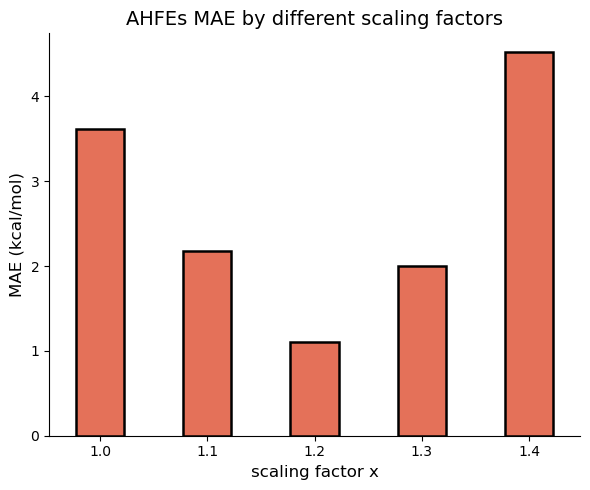

In [ ]:
df = pd.read_csv('ulkn_allscalingfactor.csv')
base_val = -df['ml_gas (kcal/mol)'] + df['mm_hfe (kcal/mol)']
solv_cols = [col for col in df.columns if 'ml_solv' in col]

mae_results = {}


for col in solv_cols:
    raw_suffix = col.split('_')[2].split(' ')[0] 
    suffix = f"{float(raw_suffix) / 10:.1f}"
    
    predicted_val = base_val + df[col]
    abs_error = np.abs(predicted_val - df['exp (kcal/mol)'])

    mae_results[suffix] = abs_error.mean()


# 转换为 Series
mae_series = pd.Series(mae_results)


plt.figure(figsize=(6, 5))


mae_series.plot(kind='bar', color='#e47159', edgecolor='black', width=0.45, linewidth=1.8)

plt.title('AHFEs MAE by different scaling factors', fontsize=14)
plt.ylabel('MAE (kcal/mol)', fontsize=12)
plt.xlabel('scaling factor x', fontsize=12)
plt.xticks(rotation=0) 
plt.tight_layout()

ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.show()

# plt.savefig('scaling_factor.svg')